In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(r'C:\Users\ASUS\OneDrive\Desktop\python_project\ai4i2020.csv')
data = pd.DataFrame(df)

In [3]:
data.head(5)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
data.shape

(10000, 14)

In [5]:
data.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [6]:
data.info

<bound method DataFrame.info of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  

In [7]:
data.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [10]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [11]:
data["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [18]:
failure_percentage = data["Machine failure"].mean() * 100
failure_percentage

print(f"Machine Failure Rate: {failure_percentage:.2f}%")

Machine Failure Rate: 3.39%


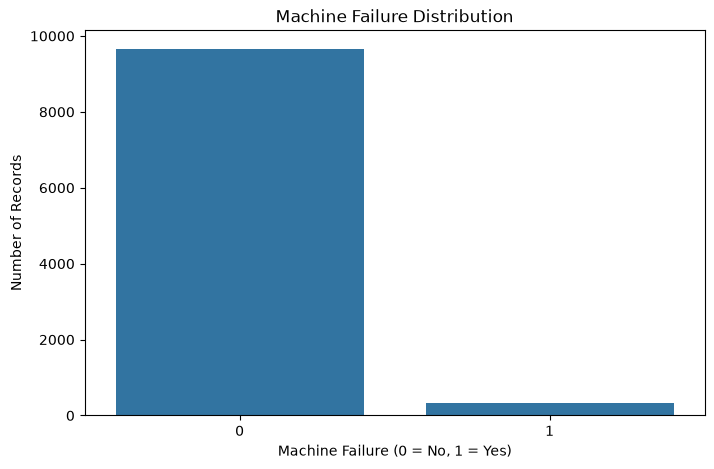

In [25]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

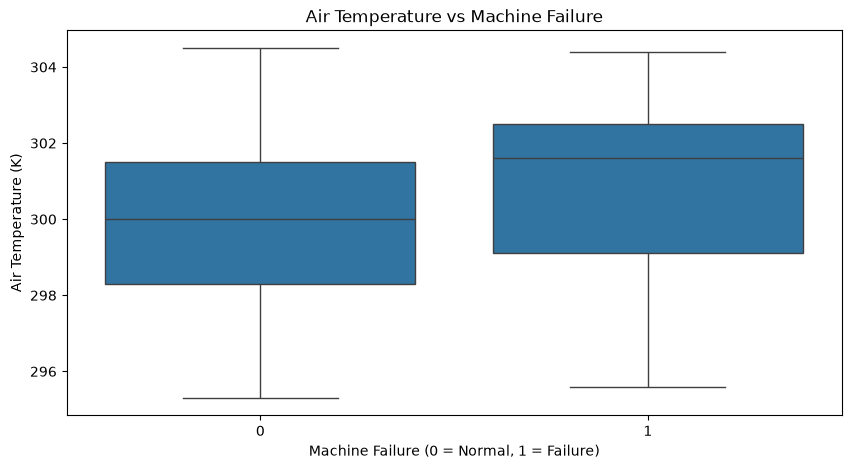

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature [K]"
)

plt.title("Air Temperature vs Machine Failure")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Air Temperature (K)")

plt.show()

In [27]:
df.groupby("Machine failure")[
    ["Air temperature [K]", "Process temperature [K]"]
].mean().round(2)

,Air temperature [K],Process temperature [K]
Machine failure,,
0,299.97,310.00
1,300.89,310.29


In [28]:
df.groupby("Machine failure")[
    ["Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
].mean().round(2)

,Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,
0,1540.26,39.63,106.69
1,1496.49,50.17,143.78


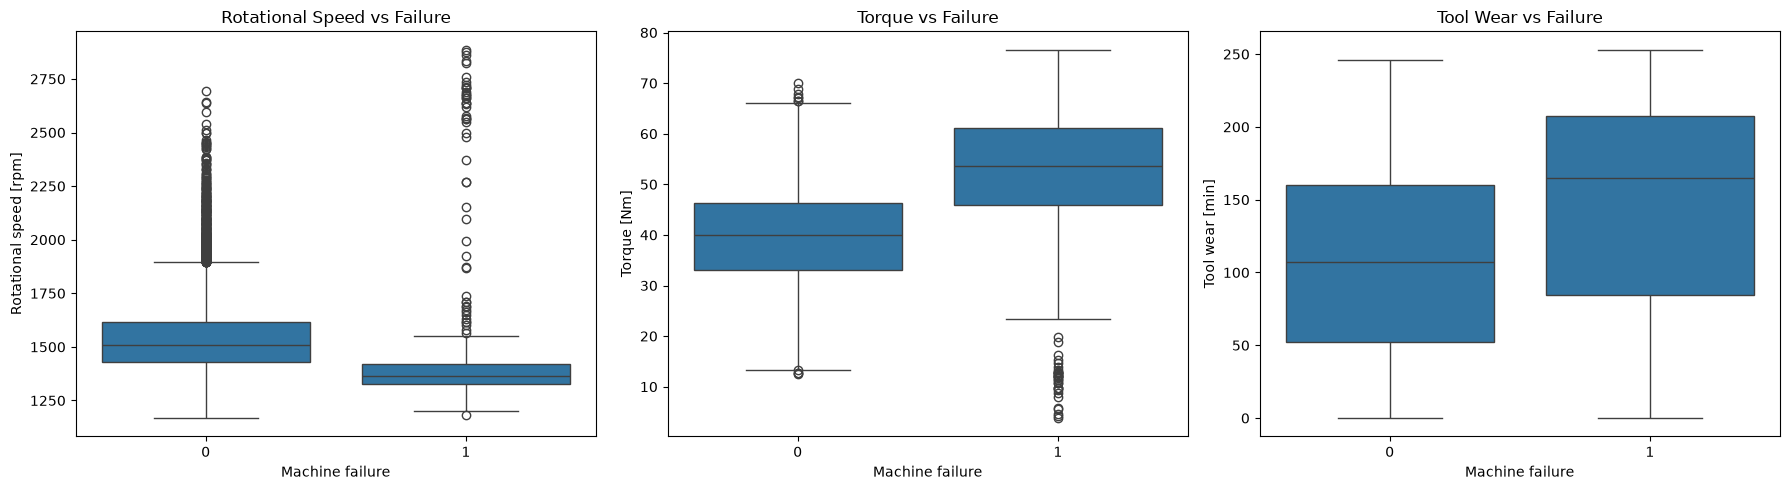

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="Machine failure",
            y="Rotational speed [rpm]", ax=axes[0])

sns.boxplot(data=df, x="Machine failure",
            y="Torque [Nm]", ax=axes[1])

sns.boxplot(data=df, x="Machine failure",
            y="Tool wear [min]", ax=axes[2])

axes[0].set_title("Rotational Speed vs Failure")
axes[1].set_title("Torque vs Failure")
axes[2].set_title("Tool Wear vs Failure")

plt.tight_layout()
plt.show()

In [33]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

y = df["Machine failure"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 6)
Target shape: (10000,)


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 6)
X_test shape: (2000, 6)
y_train shape: (8000,)
y_test shape: (2000,)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Convert categorical Type column into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ("type", OneHotEncoder(handle_unknown="ignore"), ["Type"])
    ],
    remainder="passthrough"
)

# Create machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict machine failures on test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Machine Failure"],
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 97.95 %

Classification Report:
                 precision    recall  f1-score   support

     No Failure       0.99      0.99      0.99      1932
Machine Failure       0.71      0.66      0.69        68

       accuracy                           0.98      2000
      macro avg       0.85      0.83      0.84      2000
   weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1914   18]
 [  23   45]]


                              Feature  Importance
6              remainder__Torque [Nm]    0.305896
5   remainder__Rotational speed [rpm]    0.297352
7          remainder__Tool wear [min]    0.209390
3      remainder__Air temperature [K]    0.100740
4  remainder__Process temperature [K]    0.068782
1                        type__Type_L    0.008953
2                        type__Type_M    0.005809
0                        type__Type_H    0.003077


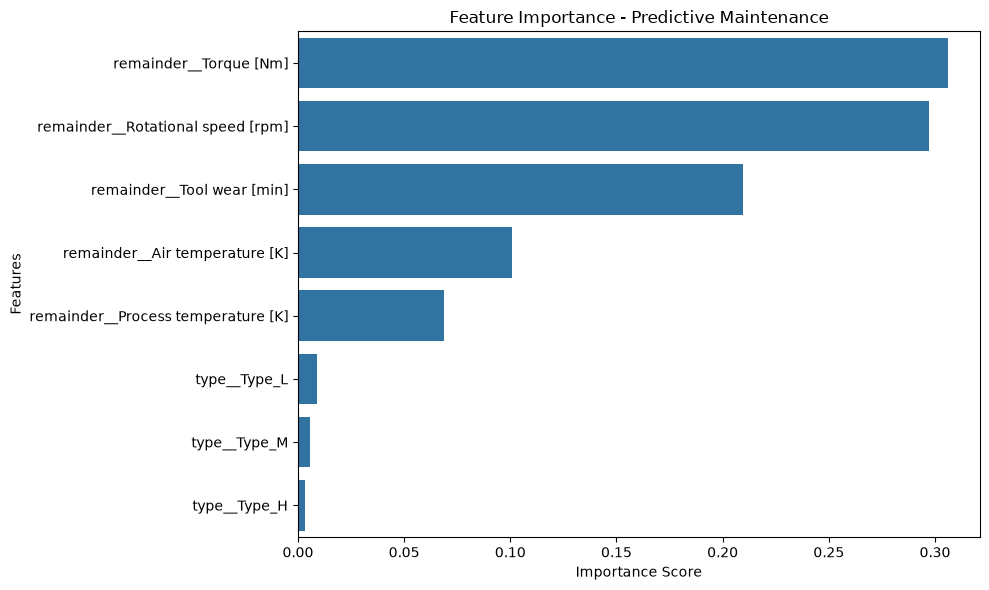

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from Random Forest
rf_model = model.named_steps["classifier"]

# Get the encoded feature names
encoded_features = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": encoded_features,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Predictive Maintenance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [39]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict failure probabilities
y_probability = model.predict_proba(X_test)[:, 1]

# Set a lower threshold
threshold = 0.30

# Convert probabilities into predictions
y_pred_new = (y_probability >= threshold).astype(int)

# Evaluate the new predictions
print("Threshold:", threshold)

print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_new) * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_new,
        target_names=["No Failure", "Machine Failure"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_new))

Threshold: 0.3
Accuracy: 96.75 %

Classification Report:
                 precision    recall  f1-score   support

     No Failure       0.99      0.97      0.98      1932
Machine Failure       0.51      0.84      0.64        68

       accuracy                           0.97      2000
      macro avg       0.75      0.91      0.81      2000
   weighted avg       0.98      0.97      0.97      2000


Confusion Matrix:
[[1878   54]
 [  11   57]]


In [41]:
import joblib

joblib.dump(model, "predictive_maintenance_model.pkl")

['predictive_maintenance_model.pkl']